# Calculate Cell Footprint Area

Standalone script for measuring the footprint area of delaminated cells from TIFF microscopy images. Uses OpenCV to:
1. Apply median blur to reduce noise
2. Apply adaptive Gaussian thresholding to segment cells
3. Detect contours and calculate the area of the cell footprint in pixels

## Requirements
```
pip install numpy pandas matplotlib opencv-python tifffile
```

## How to use
1. Update the **Configuration** cell with your image path and filename
2. Tune `blur_factor` and `cluster_size` to your image — run cells incrementally to check segmentation quality
3. Use the contour selection cell to identify the correct contour index (`cntr_num`)

> **Note:** Documentation was generated with AI assistance.


In [1]:
import numpy as np
import pandas as pd
import os                                           #operating system: to import and save files directly to downloads folder
import tifffile                                     #to import tiff images
import matplotlib.pyplot as plt                     #to plot and view results

import cv2 as cv                                    #for computer vision (to identify cells)
from scipy import ndimage as ndi                    #required for Euclidian Distance Transform (EDT)
from skimage.feature import peak_local_max          #required for EDT
from skimage.segmentation import watershed          #required to perform watershed (separate overlapping contours)

import scipy.signal                                 #for Savitzky-Golay smoothing of brightness over time signal
import seaborn as sb                                #for plotting 

In [ ]:
# ============================================================
# CONFIGURATION — update these before running
# ============================================================

# Path to folder containing your image file
IMAGE_DIR = "path/to/your/images"  # <-- update this

# Image filename (without extension)
IMAGE_FILENAME = "your_image_name"  # <-- update this

# File extension
TIFF_EXTENSION = "tif"


In [2]:
home_dir = os.path.expanduser("~")


In [4]:
image = cv.imread(tiff_path)

# Convert the image to grayscale if needed
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Convert the image to a DataFrame
df = pd.DataFrame(gray_image)

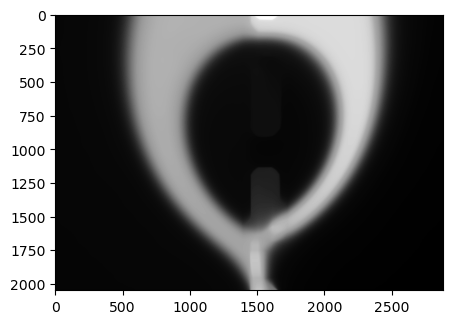

In [5]:
#must be odd number. Higher = more blurred
blur_factor = 111

#blur image
df_blurred = cv.medianBlur(df.values.astype('uint8'), blur_factor)

fig, ax = plt.subplots(figsize=(5, 5))  
ax.imshow(df_blurred, cmap='gray')

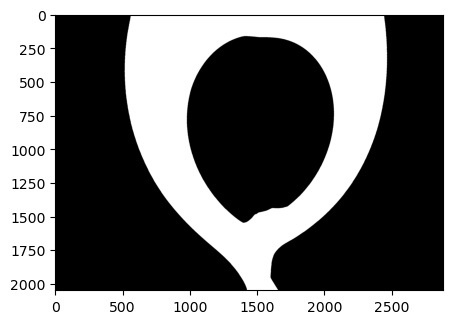

In [6]:
#Must be odd number
cluster_size = 3555

#Use Gaussian threshold, rather than Mean threshold. Works better (from observations, not understanding of how it works)
gauss_thresh = cv.adaptiveThreshold(df_blurred, 55, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, cluster_size, 2) #no idea what 2 is

fig, ax = plt.subplots(figsize=(5, 5))  
ax.imshow(gauss_thresh, cmap='gray')

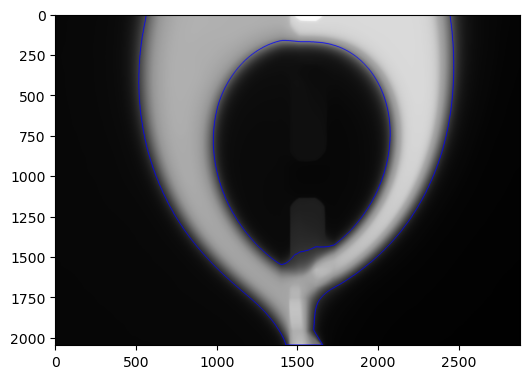

In [7]:
image = cv.cvtColor(df_blurred, cv.COLOR_GRAY2BGR)

contours, hierarchy = cv.findContours(gauss_thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

line_thickness = 3

for i, c in enumerate(contours):
    cv.drawContours(image, contours, i, (0,0,255), line_thickness)
    
# show the output image
fig, ax = plt.subplots(figsize=(6, 6))  
ax.imshow(image)

In [8]:
#Multiple contours will be created, test below to find the correct one (typically will be the last one)

print("Contours found:", hierarchy.shape[1])
print("Hierarchy levels:", hierarchy.shape[2])

print("")

for i, contour in enumerate(contours):
    if cv.contourArea(contour) > 100:
        # Calculate area
        area = cv.contourArea(contour)
        print("Area of contour", i, ":", area)

Contours found: 8
Hierarchy levels: 4

Area of contour 1 : 2884287.0
Area of contour 7 : 1152787.5


In [9]:
pick_contour = cv.cvtColor(df_blurred, cv.COLOR_GRAY2BGR)

# -1 shows all contours, after that it is 0 indexing. Figure out which contour is the correct one
cntr_num = 77

cv.drawContours(pick_contour, contours, cntr_num, (0,0,255), line_thickness)

# show the output image
fig, ax = plt.subplots(figsize=(6, 6))  
ax.imshow(pick_contour)

error: OpenCV(4.9.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\drawing.cpp:2527: error: (-215:Assertion failed) 0 <= contourIdx && contourIdx < (int)last in function 'cv::drawContours'
